In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np
import geopandas as gpd
import country_converter as coco

In [2]:
one_point_countries = pd.read_parquet("../data/by_country/one_point_countries.parquet")
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__median,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,1.535,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,1.470,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,1.165,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,-0.480,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.070,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303


In [6]:
one_point_countries['iso_a3'] = coco.convert(names=one_point_countries['Country'], to='ISO3')

New not found in ISO3
South not found in regex
South not found in regex
United not found in regex


In [7]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


In [15]:
one_point_countries.tail()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
48,Switzerland,4.958,4.97,0.041665,0.008404,4.89,5.01,5.01,0.024540,-0.522266,...,0.066068,0.032788,1.92,2.13,2.13,0.081218,0.670972,-0.661833,0.016545,CHE
49,Thailand,40.257,40.22,0.465039,0.011552,39.71,40.97,40.82,0.027953,0.205878,...,0.041425,0.195399,0.13,0.26,0.17,-0.260870,-0.581054,-0.813927,-0.010667,THA
50,Turkey,33.394,33.38,1.529223,0.045793,31.49,35.59,35.59,0.130200,0.202010,...,0.093643,-0.843630,-0.25,-0.01,-0.25,24.000000,-0.311503,-1.487279,-0.029879,TUR
51,United,34.473,34.46,0.453785,0.013163,33.88,35.19,35.19,0.038666,0.280498,...,0.144945,0.107287,1.16,1.57,1.16,-0.261146,0.190162,-1.255222,-0.048424,not found
52,USA,166.460,166.15,2.732471,0.016415,162.70,170.70,170.70,0.049170,0.200181,...,0.118085,0.086446,1.22,1.54,1.22,-0.152778,0.105426,-1.597092,-0.034667,USA


In [22]:
filtered_df = one_point_countries[one_point_countries['Country'].isin(['United', 'South'])]
filtered_df

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
44,South,25.148,24.875,1.210511,0.048135,23.79,27.14,27.14,0.140815,0.573218,...,0.142916,-9.527737,-0.26,0.13,-0.26,-3.600000,-0.751475,-1.002446,-0.043939,not found
45,South,28.801,28.705,0.582760,0.020234,28.05,29.70,29.70,0.058824,0.352545,...,0.160003,0.128723,1.02,1.40,1.40,0.372549,-0.469098,-1.620614,0.050970,not found
51,United,34.473,34.460,0.453785,0.013163,33.88,35.19,35.19,0.038666,0.280498,...,0.144945,0.107287,1.16,1.57,1.16,-0.261146,0.190162,-1.255222,-0.048424,not found


In [20]:
south_africa_df = pd.read_parquet('../data/by_country/South_Africa_macro_profile.parquet')
south_korea_df = pd.read_parquet('../data/by_country/South_Korea_macro_profile.parquet')

In [21]:
labor_force_sa = south_africa_df['labor_force'].mean()
labor_force_sk = south_korea_df['labor_force'].mean()
print(f"South Africa labor force mean:{labor_force_sa}.\nSouth Korea labor force mean:{labor_force_sk}")

South Africa labor force mean:25.06875.
South Korea labor force mean:28.7825


In [24]:
# search for the indeces where we have'South' y 'United'
indices_south = one_point_countries[one_point_countries['Country'] == 'South'].index.tolist()
indice_united = one_point_countries[one_point_countries['Country'] == 'United'].index[0]

# replace theis values according to the order identified
one_point_countries.loc[indices_south[0], 'Country'] = 'South Africa'
one_point_countries.loc[indices_south[1], 'Country'] = 'South Korea'
one_point_countries.loc[indice_united, 'Country'] = 'United Kingdom'

In [26]:
one_point_countries[one_point_countries['Country'].isin(['United Kingdom', 'South Africa', 'South Korea'])]

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
44,South Africa,25.148,24.875,1.210511,0.048135,23.79,27.14,27.14,0.140815,0.573218,...,0.142916,-9.527737,-0.26,0.13,-0.26,-3.600000,-0.751475,-1.002446,-0.043939,not found
45,South Korea,28.801,28.705,0.582760,0.020234,28.05,29.70,29.70,0.058824,0.352545,...,0.160003,0.128723,1.02,1.40,1.40,0.372549,-0.469098,-1.620614,0.050970,not found
51,United Kingdom,34.473,34.460,0.453785,0.013163,33.88,35.19,35.19,0.038666,0.280498,...,0.144945,0.107287,1.16,1.57,1.16,-0.261146,0.190162,-1.255222,-0.048424,not found


In [27]:
one_point_countries['iso_a3'] = coco.convert(names=one_point_countries['Country'], to='ISO3')

New not found in ISO3


In [28]:
one_point_countries['Country'] = one_point_countries['Country'].replace('New', 'New Zealand')
one_point_countries['iso_a3'] = coco.convert(names=one_point_countries['Country'], to='ISO3')

In [29]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


In [35]:
# load geodata
world = gpd.read_file("../data/geo_data/ne_110m_admin_0_countries.shp")


# merge our data with geodata
world = world.merge(one_point_countries, left_on='iso_a3', right_on='iso_a3')

# 5. Plotear mapa coroplético
world.plot(column='labor_force_growth', cmap='OrRd', legend=True, figsize=(15,10))
plt.title("Crecimiento de la fuerza laboral por país")
plt.axis('off')
plt.show()

KeyError: 'iso_a3'

In [37]:
print(list(world.columns))

['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', 'ADM0_A3_EG', 'ADM0_A3_MA', 'ADM0_A3_PT', 'ADM0_A3_AR', 'ADM0_A3_JP', 'ADM0_A3_KO', 'ADM0_A3_VN', 'ADM0_A3_TR', 'AD

In [ ]:
# merge our data with geodata
world = world.merge(one_point_countries, left_on='ISO_A3', right_on='iso_a3')

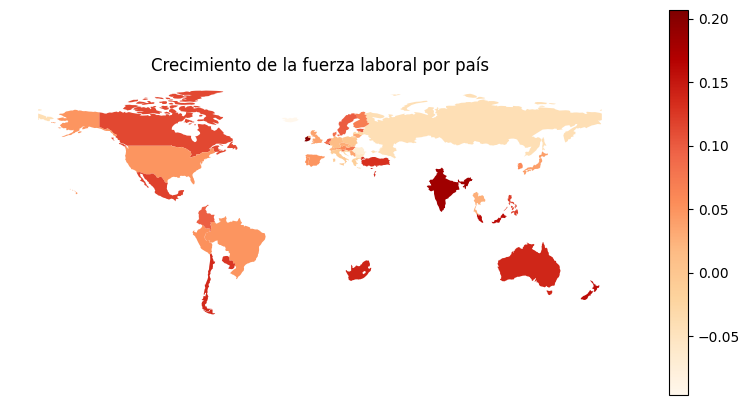

In [43]:
# 5. Plotear mapa coroplético
world.plot(column='labor_force_growth', cmap='OrRd', legend=True, figsize=(10,5))
plt.title("Crecimiento de la fuerza laboral por país")
plt.axis('off')
plt.show()

In [48]:
world[['NAME','CONTINENT','iso_a3', 'gdp_mean']].head()

,NAME,CONTINENT,iso_a3,gdp_mean
0,Canada,North America,CAN,607.98300
1,United States of America,North America,USA,5625.15975
2,Chile,South America,CHL,54722.46925
3,Russia,Europe,RUS,30836.92500
4,South Africa,Africa,ZAF,1450.81375
